# Thresholding

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### Simple thresholding

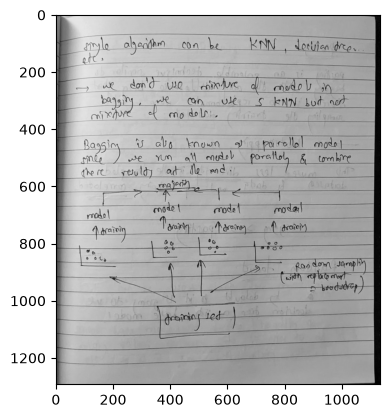

In [2]:
img = cv2.imread('./data/handwritten.jpeg', 0)
plt.imshow(img, 'grey')

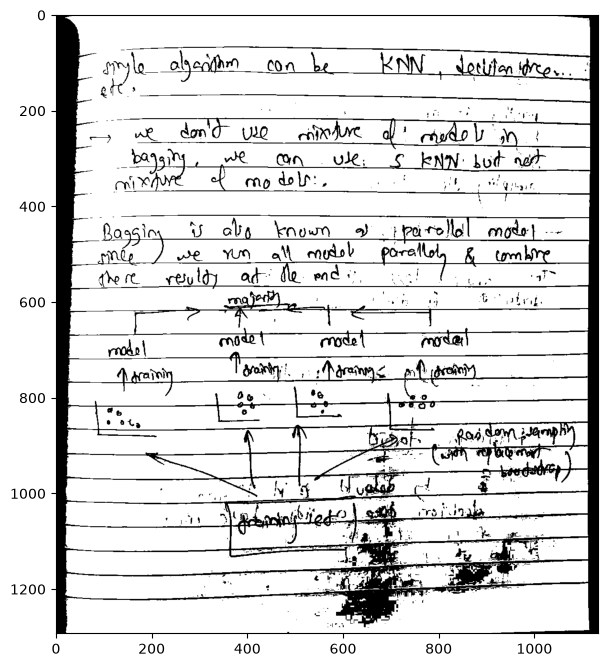

In [3]:
retval, binary_msk = cv2.threshold(src=img, thresh=150, maxval=255, type=cv2.THRESH_BINARY)
'''
255 if pixel > 150, else 0
'''
plt.figure(figsize=(7,12))
plt.imshow(binary_msk, 'grey')

### Adaptive thresholding

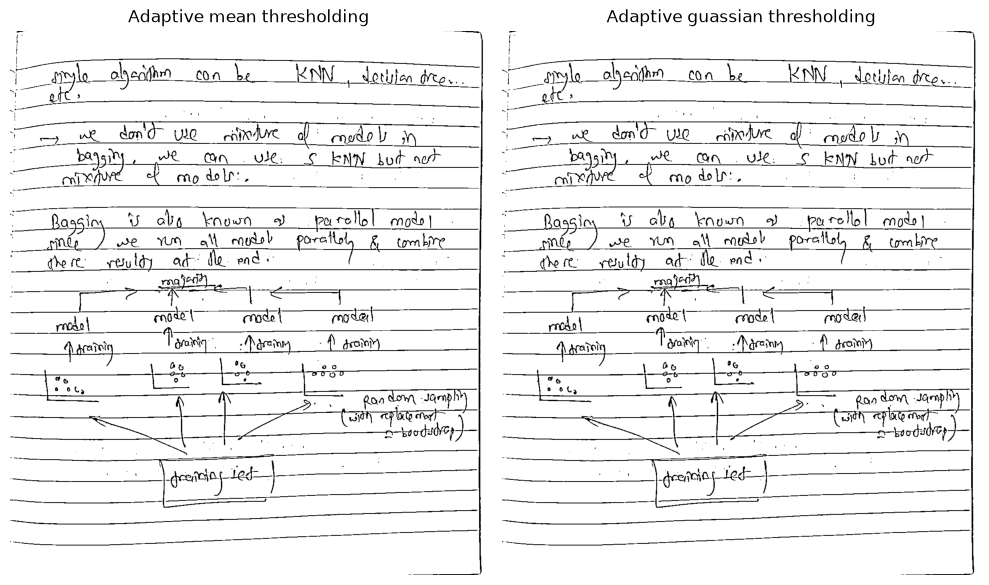

In [4]:
adapt_mean = cv2.adaptiveThreshold(src=img, # Input 8-bit single-channel (grayscale) image
                                   maxValue=255, # Output value assigned to pixels classified as foreground
                                   adaptiveMethod=cv2.ADAPTIVE_THRESH_MEAN_C, # Calculate the local threshold using the neighborhood mean
                                   thresholdType=cv2.THRESH_BINARY, # Pixels above the local threshold become 255; others become 0
                                   blockSize=11,  # Size of the local neighborhood (11 × 11 pixels); must be an odd integer greater than 1
                                   C=25) # Constant subtracted from the calculated local threshold

adapt_gaus = cv2.adaptiveThreshold(src=img, # Input 8-bit single-channel (grayscale) image
                                   maxValue=255, # Output value assigned to pixels classified as foreground
                                   adaptiveMethod=cv2.ADAPTIVE_THRESH_MEAN_C, # Calculate the local threshold using a Gaussian-weighted sum of neighborhood pixels
                                   thresholdType=cv2.THRESH_BINARY, # Pixels above the local threshold become 255; others become 0
                                   blockSize=11,  # Size of the local neighborhood (11 × 11 pixels); must be an odd integer greater than 1
                                   C=25) # Constant subtracted from the calculated local threshold


plt.figure(figsize=(10, 24))

plt.subplot(1,2,1)
plt.imshow(adapt_mean, cmap='grey')
plt.title("Adaptive mean thresholding")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(adapt_gaus, cmap='grey')
plt.title("Adaptive guassian thresholding")
plt.axis('off')

plt.tight_layout()
plt.show()

# kmeans clustering

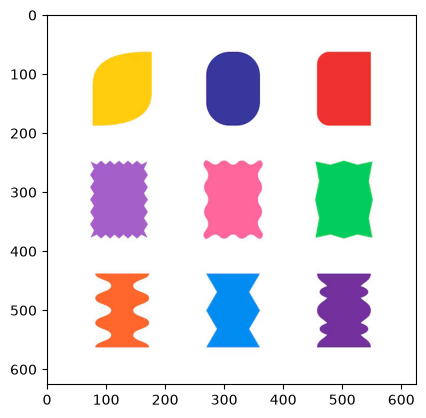

In [5]:
img = cv2.imread('./data/shapes.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)

In [6]:
print(img.shape) # 3-dimension data

(626, 626, 3)


In [7]:
# Prepare data for kmeans clustering algorithm
pixel_val = img.reshape((-1,3)).astype(np.float32) # suitable data type for OpenCV's K-Means implementation
print(pixel_val.shape) # 2-dimension data

(391876, 3)


In [8]:
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
'''
NOTE: Define the termination criteria for the K-Means algorithm. As per documentation:

--> criteria = (type, maxCount, epsilon)

cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER
--> Stop when either the required accuracy is reached or the maximum number of iterations is reached

100
--> Maximum number of iterations allowed

0.2
--> Epsilon: Stop if the cluster centers change by less than this threshold

'''

k = 3 # number of clusters

_, labels, centers = cv2.kmeans(data=pixel_val, # pixel color values, typically shaped (number_of_pixels, 3) and converted to float32
                                K=k, # number of clusters to create
                                bestLabels=None, # no initial cluster assignments are provided; OpenCV initializes them based on the selected flags
                                criteria=criteria, # termination criteria controlling when the algorithm stops
                                attempts=10, # run the algorithm 10 times with different initial cluster centers and retain the best result
                                flags=cv2.KMEANS_RANDOM_CENTERS) # initialize cluster centers randomly

In [9]:
print(labels.shape)
print(centers) # 3 clusters with XYZ values

(391876, 1)
[[ 70.9147   110.96521  167.68669 ]
 [255.2777   255.2192   255.20657 ]
 [249.43346  114.88152   69.147255]]


In [10]:
np.unique(labels.flatten(), return_counts=True)

(array([0, 1, 2], dtype=int32), array([ 51279, 299214,  41383]))

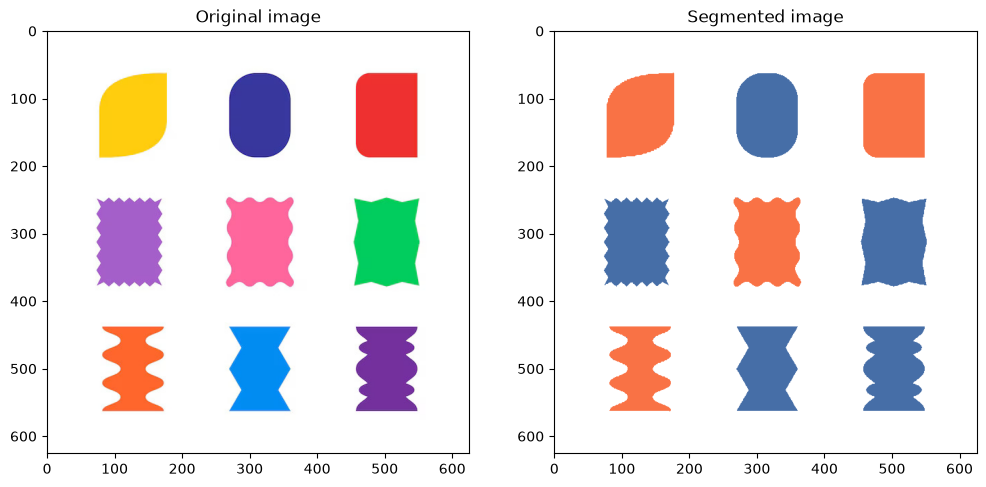

In [11]:
# Reconstruct the image
centers = np.uint8(centers) # convert to 8-bit unsigned integer
segmented_img = centers[labels.flatten()].reshape(img.shape)

# Label indexing
# 0 --> [70,110, 167]
# 1 --> [255, 255, 255]
# 2 --> [249 114  69]

plt.figure(figsize=(12,7))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original image")

plt.subplot(1,2,2)
plt.imshow(segmented_img)
plt.title("Segmented image")

plt.show()

In the image, only can see 2 categories. The remaining one is the whole image itself.

# watershed algorithm

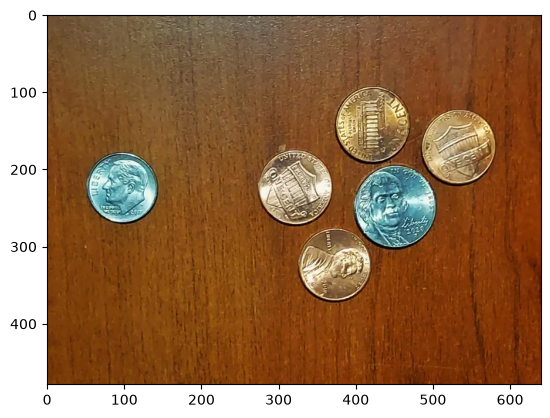

In [12]:
img = cv2.imread('./data/coin2.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
original_img = img_rgb.copy()
plt.imshow(original_img)

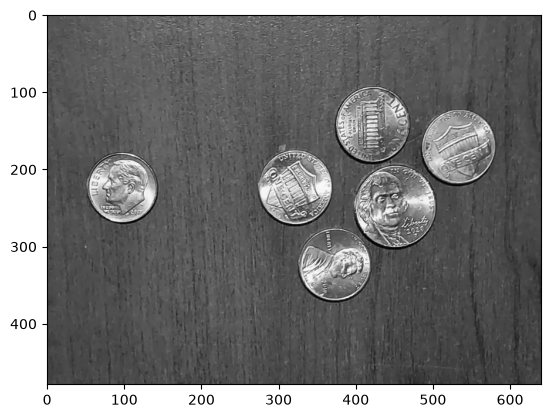

In [13]:
img_grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(img_grey, 'gray')

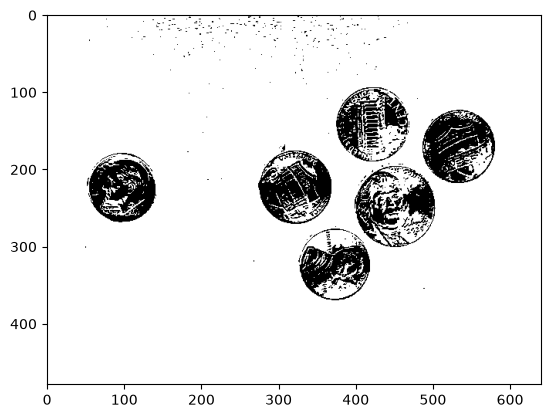

In [14]:
_, thresh = cv2.threshold(src=img_grey, # input 8-bit single-channel (grayscale) image
                          thresh=130,   # pixels > 130 = 0; pixels ≤ 0 = 255
                          maxval=255,   # maximum output value assigned to pixels that meet the inverse threshold condition
                          type=cv2.THRESH_BINARY_INV) # inverse binary thresholding: pixels > 130 = 0; pixels ≤ 130 = 255

plt.imshow(thresh, cmap='grey')

In [15]:
kernel = np.ones((3,3), np.uint8)

# Remove small white noise and tiny foreground objects from a binary image using a morphological operation called Opening
opening = cv2.morphologyEx(src=thresh, 
                           op=cv2.MORPH_OPEN, # perform morphological opening: erosion followed by dilation
                           kernel=kernel, # structuring element that defines the neighborhood used for the operation
                           iterations=3) # repeat the opening operation 4 times

**NOTE**: 
- Erosion $\to$ shrink white object
- Dilation $\to$ expand white object

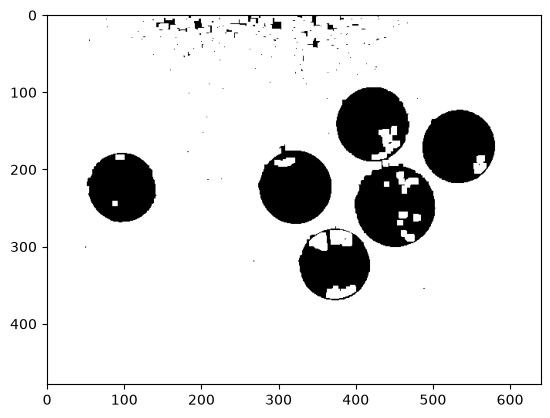

In [16]:
plt.imshow(opening, 'grey')

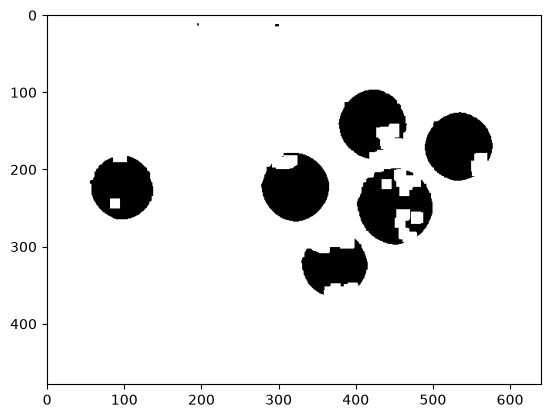

In [17]:
sure_bg = cv2.dilate(src=opening, kernel=kernel, iterations=3)
plt.imshow(sure_bg, 'grey')

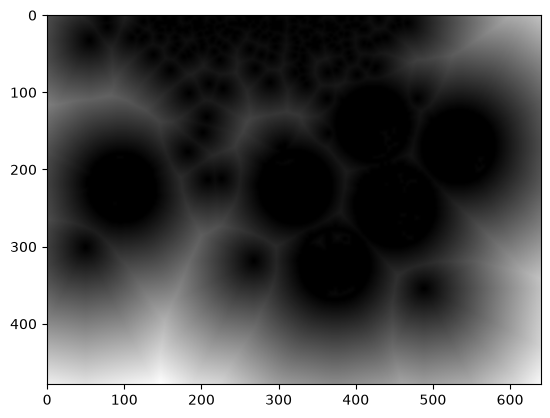

In [19]:
# Calculate the distance from each foreground pixel to the nearest background pixel
dist_transform = cv2.distanceTransform(src=opening, 
                                       distanceType=cv2.DIST_L2, # use Euclidean distance to measure the distance to the nearest zero pixel
                                       maskSize=5) # use a 5 × 5 mask to approximate the Euclidean distance
plt.imshow(dist_transform, 'grey')

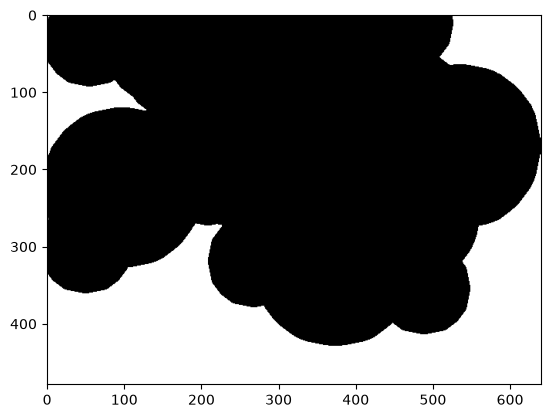

In [20]:
# Apply binary thresholding to the distance transform to identify sure foreground regions
_, sure_fg = cv2.threshold(src=dist_transform, 
                           thresh=0.3 * dist_transform.max(), # Threshold at 30% of the maximum distance value
                           maxval=255,  # assign 255 to pixels that exceed the threshold
                           type=cv2.THRESH_BINARY) # # pixels above the threshold become 255; all others become 0

sure_fg = np.uint8(sure_fg)

plt.imshow(sure_fg, cmap='grey')

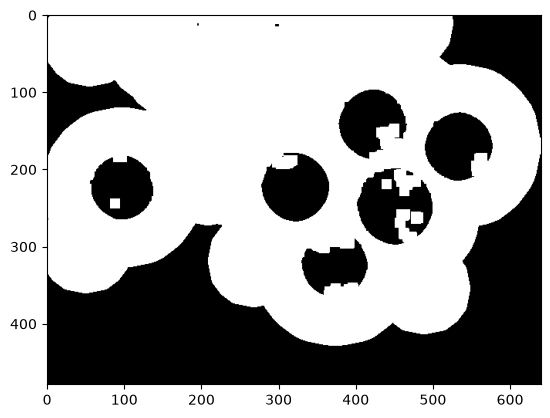

In [21]:
unknown = cv2.subtract(sure_bg, sure_fg)
plt.imshow(unknown, cmap='grey')

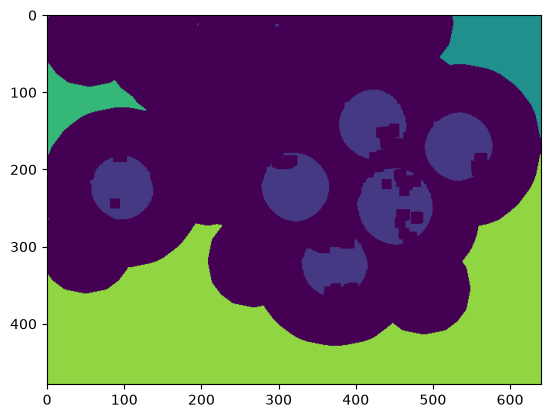

In [22]:
# Identify connected foreground components in the sure foreground image
_, markers = cv2.connectedComponents(image=sure_fg)  # Binary image containing the sure foreground regions
# The unique values of markers --> 0,1,2,3,4,5

# Add 1 to every marker label so that the background becomes 1 instead of 0
markers = markers + 1 # unique values --> 1,2,3,4,5,6

# Mark unknown regions as 0 so watershed can determine their labels
markers[unknown == 255] = 0

plt.imshow(markers)

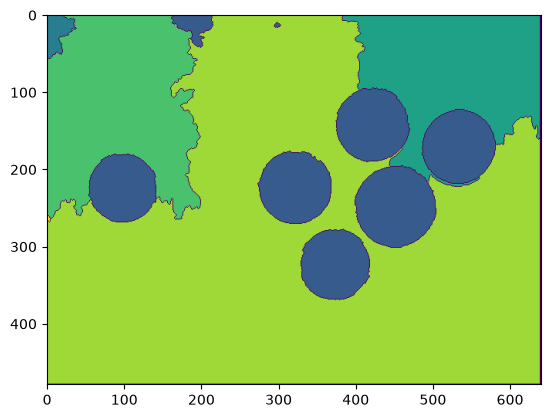

In [23]:
# Apply watershed segmentation to separate objects and identify their boundaries
markers = cv2.watershed(img, markers) # unique values: [-1  1  2  3  4  5  6]
# -1 --> watershed boundary between regions
# 1 --> Background marker, assuming you shifted the original labels by 1
# 2 to 6 --> Foreground regions or other labeled regions
plt.imshow(markers)

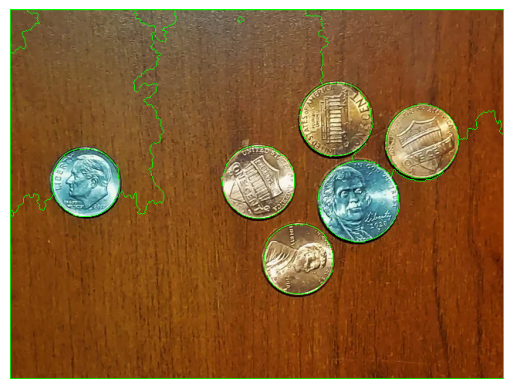

In [24]:
# Highlight watershed boundaries in red (BGR color)
image = img.copy()
image[markers == -1] = [0, 255, 0]

# Display the segmented image
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [45]:
coin_mask = np.zeros_like(img_grey)
print(img_grey.shape, coin_mask.shape)
np.unique(coin_mask)

(479, 640) (479, 640)


array([0], dtype=uint8)

In [26]:
unique_labels = np.unique(markers)
unique_labels

array([-1,  1,  2,  3,  4,  5,  6], dtype=int32)

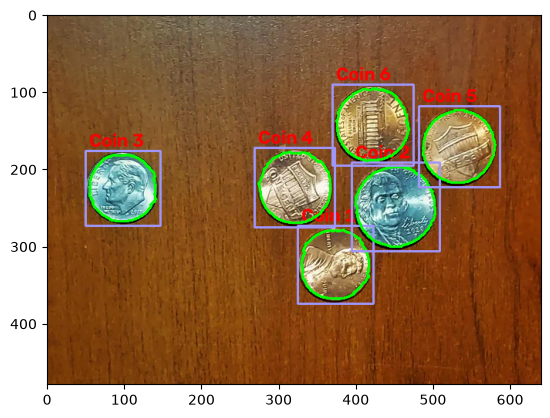

In [52]:
original_img = img_rgb.copy()
instance_number = 1 # initialize the coin counter, starting from Coin 1
font = cv2.FONT_HERSHEY_SIMPLEX # select the font used to display coin labels

for label in unique_labels:
    # Skip label 0 (unknown/unassigned regions, if present)
    # and label -1 (watershed boundaries)
    if label == 0 or label == -1:
        continue

    mask = np.uint8(markers == label) # converts the Boolean values into 8-bit integers

    # Detect the outer boundary of the current segment region
    contours, _ = cv2.findContours(image=mask, 
                                   mode=cv2.RETR_EXTERNAL, # retrieves outermost contours, ignoring inner contours 
                                   method=cv2.CHAIN_APPROX_SIMPLE) # compresses contour points by retaining essential points, 
                                                                   # such as the endpoints of straight lines.
    for contour in contours:
        # Calculates the area enclosed by the contour
        area = cv2.contourArea(contour)

        # Calculate the perimeter
        perimeter = cv2.arcLength(curve=contour, closed=True)

        # Prevents division by zero when calculating circularity
        if perimeter == 0:
            continue

        # Measures how closely the contour resembles a circle.
        circularity = 4 * np.pi * (area / (perimeter * perimeter))

        if 0.7 < circularity < 1.1 and area > 1000:
            cv2.drawContours(image=original_img, 
                             contours=[contour], # a list containing the current contour.
                             contourIdx=-1,      # draws all contours provided in the list
                             color=(0,255,0),    # green in OpenCV's BGR color format.
                             thickness=2)        # sets the outline thickness to 2 pixels.

            # Calculate the bounding rectangle
            x, y, w, h = cv2.boundingRect(contour)

            # Add a text label to the image to identify the detected coin
            cv2.putText(img=original_img,                # Image on which the text will be drawn
                        text=f"Coin {instance_number}",  # Text to display, e.g., "Coin 1"
                        org=(x, y-10),                   # Bottom-left coordinates of the text in (x, y) format
                        fontFace=font,                   # Font style used to display the text
                        fontScale=0.8,                   # Font size scale factor
                        color=(255, 0, 0),               # Text color in BGR format (blue)
                        thickness=2)                     # Thickness of the text strokes in pixels

            coin_mask = cv2.bitwise_or(coin_mask, mask)

            # Draw a rectangle around the detected coin
            cv2.rectangle(img=original_img,        # Image on which the rectangle will be drawn
                          pt1=(x-5, y-5),          # Top-left corner, with a 5-pixel margin
                          pt2=(x+w+5, y+h+5),      # Bottom-right corner, with a 5-pixel margin
                          color=(160, 150, 250),   # Rectangle color in BGR format
                          thickness=2)             # Thickness of the rectangle border in pixels

            instance_number += 1
            

plt.imshow(original_img)

The formula is:
$$\boxed{C = \frac{4\pi A}{P^2}}$$

$$A=\pi r^2,\qquad P=2\pi r$$

Where:
- C = circularity
- A = contour area
- P = contour perimeter
- $\pi$ ≈ 3.14159

Circularity generally ranges from near 0 for elongated or irregular shapes to 1 for a perfect circle.

| Shape | Approximate circularity |
|---|---:|
| Perfect circle | 1.00 |
| Nearly circular object | 0.85–0.95 |
| Square | 0.79 |
| Long, thin object | Much closer to 0 |

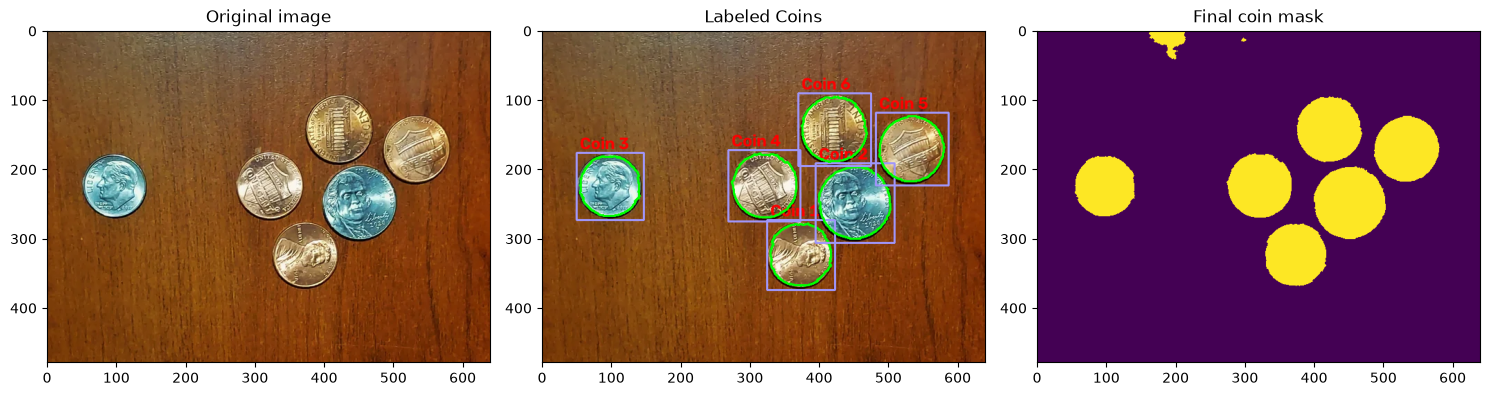

In [54]:
plt.figure(figsize=(15,10))

plt.subplot(1,3,1)
plt.imshow(img_rgb)
plt.title("Original image")

plt.subplot(1,3,2)
plt.imshow(original_img)
plt.title("Labeled Coins")

plt.subplot(1,3,3)
plt.imshow(coin_mask)
plt.title("Final coin mask")

plt.tight_layout()
plt.show()